# 10 — Etapa 3: caracterización temporal y operacional de las desviaciones (HAI22.04)

**Propósito:** describir **cuándo**, **durante cuánto tiempo** y **en qué componentes** se concentran las discrepancias respecto del comportamiento predicho. No pretende certificar fallas, reconocer regímenes específicos ni atribuir causas físicas.

**Protocolo congelado:** modelos FULL `DT`, `RF`, `ET`, `XGB` y `PERSIST`; evaluación únicamente en `test2`, `test3` y `test4`; calibración y umbrales **originales**, provenientes del último 20 % de TRAIN1. No se entrena, predice, recalibra ni modifica ningún dato.

**Fuentes:** `deteccion/{MODELO}_FULL_testN.csv.gz`, `predicciones/{MODELO}_FULL_testN.csv.gz`, `deteccion/umbral_{MODELO}_FULL.json` y, para verificación, `metricas/deteccion_{MODELO}_FULL.csv`. Se verifica correspondencia exacta de índices y etiquetas antes de calcular estadísticas.

**Salida:** tablas CSV, dos figuras y comprobaciones en `analisis/etapa_3`. Una fila señalada significa solamente **error multivariable superior al umbral del modelo**, no una falla industrial confirmada.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles")
OUT = ROOT / "analisis" / "etapa_3"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = ("DT", "RF", "ET", "XGB", "PERSIST")
TESTS = ("test2", "test3", "test4")
COMPONENTS = ("P1", "P2", "P3", "P4")
EXPECTED = {(m,t) for m in MODELS for t in TESTS}

assert (ROOT / "deteccion").is_dir(), "No existe el directorio de detección"
assert (ROOT / "predicciones").is_dir(), "No existe el directorio de predicciones"
print('Resultados:', ROOT)
print('Salida:', OUT)


Resultados: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles
Salida: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles\analisis\etapa_3


## 1. Funciones de lectura y comprobación

Se verifica que las 15 series de detección estén completas y que la señalización por registro coincida con las métricas originales. Los archivos GZIP se leen sin descomprimirlos en disco.

In [2]:
def source_file(folder, stem):
    for ext in (".csv.gz", ".csv"):
        p = ROOT / folder / (stem + ext)
        if p.is_file():
            return p
    raise FileNotFoundError(f"Falta {folder}/{stem}.csv.gz")

def read_data(p, **kwargs):
    with p.open('rb') as f:
        is_gzip = f.read(2) == b'\x1f\x8b'
    return pd.read_csv(p, compression='gzip' if is_gzip else None, **kwargs)

def require_columns(df, names, origin):
    missing = set(names) - set(df.columns)
    if missing:
        raise ValueError(f"{origin}: faltan columnas {sorted(missing)}")

def runs_from_flags(indices, flags):
    """Rachas consecutivas en índices del mismo archivo; jamás unen TEST diferentes."""
    idx = np.asarray(indices, dtype=np.int64)
    state = np.asarray(flags, dtype=bool)
    if len(idx) != len(state) or len(idx) == 0 or np.any(np.diff(idx) <= 0):
        raise ValueError('Índices vacíos, repetidos, desordenados o dimensiones incompatibles')
    start = state & np.r_[True, (~state[:-1]) | (np.diff(idx) != 1)]
    end = state & np.r_[(~state[1:]) | (np.diff(idx) != 1), True]
    begins, finishes = np.flatnonzero(start), np.flatnonzero(end)
    assert len(begins) == len(finishes)
    return list(zip(begins, finishes))

thresholds = {}
for model in MODELS:
    path = ROOT / "deteccion" / f"umbral_{model}_FULL.json"
    if not path.is_file():
        raise FileNotFoundError(f"Falta umbral original: {path}")
    thresholds[model] = json.loads(path.read_text(encoding='utf-8'))
    for test in TESTS:
        source_file('deteccion', f'{model}_FULL_{test}')
        source_file('predicciones', f'{model}_FULL_{test}')
print('Se encontraron los 15 pares de archivos y los cinco umbrales originales.')


Se encontraron los 15 pares de archivos y los cinco umbrales originales.


## 2. Continuidad temporal de las desviaciones

Un **intervalo señalado** es una secuencia de registros consecutivos con `alerta=1` dentro del mismo TEST y método. Como HAI registra una observación por segundo, la cantidad de registros coincide con la duración nominal en segundos **solo si** no existen discontinuidades temporales. El notebook verifica los saltos de timestamp: ante una discontinuidad, separa las rachas y no supone continuidad temporal.

No se aplica filtrado por persistencia ni se modifican las señales originales de detección.

In [3]:
series = {}
summary_rows, run_rows, block_rows, coverage_rows = [], [], [], []

for model in MODELS:
    ref_path = ROOT / 'metricas' / f'deteccion_{model}_FULL.csv'
    if not ref_path.exists():
        raise FileNotFoundError(f'Falta resumen original: {ref_path}')
    ref = pd.read_csv(ref_path)
    require_columns(ref, ('archivo','n','n_alerta'), ref_path.name)
    for test in TESTS:
        path = source_file('deteccion',f'{model}_FULL_{test}')
        d = read_data(path)
        require_columns(d, ('indice','timestamp','score','alerta','Attack'), path.name)
        d = d[['indice','timestamp','score','alerta','Attack']].copy()
        for col in ('indice','score','alerta','Attack'):
            d[col] = pd.to_numeric(d[col],errors='raise')
        d['timestamp'] = pd.to_datetime(d.timestamp, errors='raise')
        if d.isna().any().any() or not d.alerta.isin([0,1]).all() or not d.Attack.isin([0,1]).all():
            raise ValueError(f'Valores ausentes o indicadores no binarios: {path.name}')
        ix = d.indice.to_numpy(dtype=np.int64)
        if len(d)==0 or np.any(np.diff(ix)!=1):
            raise ValueError(f'Índices no consecutivos en {path.name}')
        timing = d.timestamp.diff().dt.total_seconds().to_numpy()
        gaps = int(np.count_nonzero((timing[1:] != 1)))
        if gaps:
            raise ValueError(f'{path.name}: {gaps} discontinuidades temporales; se requiere revisión')
        match = ref[ref.archivo.astype(str).str.lower()==test]
        if len(match)!=1: raise ValueError(f'Resumen duplicado o ausente: {model} {test}')
        flag = d.alerta.to_numpy(dtype=bool)
        if len(d)!=int(match.n.iloc[0]) or int(flag.sum())!=int(match.n_alerta.iloc[0]):
            raise ValueError(f'No coincide con el resumen original: {model} {test}')
        series[(model,test)]=d
        detected = runs_from_flags(ix,flag)
        lengths = np.array([b-a+1 for a,b in detected],dtype=int)
        labeled = d.Attack.to_numpy(dtype=bool)
        for a,b in detected:
            run_rows.append({'modelo':model,'test':test,'inicio_indice':int(ix[a]),
                 'fin_indice':int(ix[b]),'inicio_timestamp':str(d.timestamp.iloc[a]),
                 'fin_timestamp':str(d.timestamp.iloc[b]),'registros':int(b-a+1),
                 'coincide_alguna_etiqueta':int(labeled[a:b+1].any()),
                 'registros_dentro_etiqueta':int(labeled[a:b+1].sum())})
        summary_rows.append({'modelo':model,'test':test,'registros':len(d),
             'registros_senalados':int(flag.sum()),'porcentaje_senalado':float(100*flag.mean()),
             'intervalos_senalados':len(detected),'longitud_mediana_registros':float(np.median(lengths)) if len(lengths) else 0.,
             'longitud_p90_registros':float(np.percentile(lengths,90)) if len(lengths) else 0.,
             'longitud_max_registros':int(lengths.max()) if len(lengths) else 0,
             'registros_senalados_fuera_etiqueta':int((flag & ~labeled).sum()),
             'registros_senalados_dentro_etiqueta':int((flag & labeled).sum())})
        # Bloques de 10 minutos, anclados al primer registro del propio TEST.
        segment = (np.arange(len(d)) // 600).astype(int)
        btab = pd.DataFrame({'bloque':segment,'senalado':flag.astype(int),'attack':labeled.astype(int)})
        agg = btab.groupby('bloque',sort=True).agg(registros=('senalado','size'),
                 senalados=('senalado','sum'),etiquetados=('attack','sum')).reset_index()
        for r in agg.itertuples(index=False):
            block_rows.append({'modelo':model,'test':test,'bloque_10min':int(r.bloque),
                'inicio_timestamp':str(d.timestamp.iloc[int(r.bloque)*600]),
                'registros':int(r.registros),'senalados':int(r.senalados),
                'etiquetados':int(r.etiquetados),
                'porcentaje_senalado':100*int(r.senalados)/int(r.registros)})
        coverage_rows.append({'modelo':model,'test':test,'registros':len(d),'saltos_timestamp':gaps,
            'indices_estrictamente_consecutivos':True,'coincide_resumen_deteccion':True})

summary = pd.DataFrame(summary_rows)
intervals = pd.DataFrame(run_rows)
blocks = pd.DataFrame(block_rows)
coverage = pd.DataFrame(coverage_rows)
assert set(map(tuple,coverage[['modelo','test']].to_numpy())) == EXPECTED
assert len(coverage)==15
summary.to_csv(OUT/'01_continuidad_temporal.csv',index=False)
intervals.to_csv(OUT/'02_intervalos_senalados.csv',index=False)
blocks.to_csv(OUT/'03_bloques_temporales.csv',index=False)
coverage.to_csv(OUT/'00_cobertura.csv',index=False)
print(summary.to_string(index=False))
print('Intervalos individuales:',len(intervals))


 modelo  test  registros  registros_senalados  porcentaje_senalado  intervalos_senalados  longitud_mediana_registros  longitud_p90_registros  longitud_max_registros  registros_senalados_fuera_etiqueta  registros_senalados_dentro_etiqueta
     DT test2      82770                  998             1.205751                   476                         1.0                     3.0                     169                                 833                                  165
     DT test3      62370                 1048             1.680295                   363                         1.0                     2.0                     128                                 440                                  608
     DT test4     129570                23217            17.918500                  3815                         2.0                    11.0                    1090                               22190                                 1027
     RF test2      82770                 7311   

## 3. Coincidencia temporal con los episodios etiquetados

Se obtiene el número de intervalos etiquetados que contienen al menos un registro señalado, así como la proporción de registros señalados dentro de cada episodio. **La coincidencia no constituye confirmación de una anomalía física**. Se conservan explícitamente los episodios sin coincidencia.


In [4]:
episode_rows=[]
for (model,test),d in series.items():
    ix=d.indice.to_numpy(dtype=np.int64)
    labels=d.Attack.to_numpy(dtype=bool)
    flagged=d.alerta.to_numpy(dtype=bool)
    for ep_id,(a,b) in enumerate(runs_from_flags(ix,labels),start=1):
        total=b-a+1
        hits=int(flagged[a:b+1].sum())
        episode_rows.append({'modelo':model,'test':test,'episodio_ordinal':ep_id,
             'inicio_indice':int(ix[a]),'fin_indice':int(ix[b]),
             'inicio_timestamp':str(d.timestamp.iloc[a]),'fin_timestamp':str(d.timestamp.iloc[b]),
             'registros_etiquetados':total,'registros_senalados_en_episodio':hits,
             'porcentaje_del_episodio_senalado':100*hits/total,
             'coincidencia':int(hits>0)})
episodes=pd.DataFrame(episode_rows)
episodes.to_csv(OUT/'04_episodios_contraste.csv',index=False)
print(episodes.groupby('modelo').agg(episodios=('coincidencia','size'),
                coincidentes=('coincidencia','sum'),
                porcentaje_mediano_del_episodio_senalado=('porcentaje_del_episodio_senalado','median')))


         episodios  coincidentes  porcentaje_mediano_del_episodio_senalado
modelo                                                                    
DT              51            41                                  3.896104
ET              51            45                                 30.923695
PERSIST         51            45                                  2.409639
RF              51            45                                 20.000000
XGB             51            41                                 13.071895


## 4. Contribución de los componentes a la discrepancia normalizada

Para cada método se toma **sin modificar** la media, desviación estándar y orden de las 24 señales del JSON de calibración. A partir de residuos predichos y observados de FULL se calcula la contribución relativa de P1–P4 a la suma de residuos al cuadrado normalizados. Esta medida indica **qué grupo de salidas explica el valor del índice del modelo**, **no** identifica qué equipo produjo físicamente la desviación. Se calcula sobre registros señalados y se informa la concentración por componente y señal.

Se verifica numéricamente que el índice reconstruido coincide con `score` en la salida original; si falla, se interrumpe el cálculo. No se recalcula el umbral.

In [5]:
component_rows=[]; signal_rows=[]; score_checks=[]
for model in MODELS:
    settings=thresholds[model]
    for key in ('variables','mu','std','umbral'):
        if key not in settings:raise ValueError(f'Falta {key} en umbral original {model}')
    variables=list(settings['variables'])
    mu=np.asarray(settings['mu'],dtype=float)
    sd=np.asarray(settings['std'],dtype=float)
    assert len(variables)==len(mu)==len(sd)==24 and np.all(sd>0)
    belonging=np.asarray([v.split('_',1)[0] for v in variables])
    assert set(belonging)==set(COMPONENTS)
    error_cols=['error__'+v for v in variables]
    for test in TESTS:
        source=source_file('predicciones',f'{model}_FULL_{test}')
        p=read_data(source,usecols=['indice','timestamp','Attack']+error_cols)
        d=series[(model,test)]
        require_columns(p,['indice','timestamp','Attack']+error_cols,source.name)
        if len(p)!=len(d) or not np.array_equal(p.indice.to_numpy(),d.indice.to_numpy()):
            raise ValueError(f'Índices de predicción y detección distintos: {model} {test}')
        if not np.array_equal(p.Attack.to_numpy(dtype=int),d.Attack.to_numpy(dtype=int)):
            raise ValueError(f'Etiquetas de predicción y detección distintas: {model} {test}')
        if not np.array_equal(pd.to_datetime(p.timestamp).to_numpy(),d.timestamp.to_numpy()):
            raise ValueError(f'Timestamps diferentes: {model} {test}')
        err=p[error_cols].to_numpy(dtype=np.float64)
        sq=np.square((err-mu)/sd)
        score=np.sqrt(sq.mean(axis=1))
        origin=d.score.to_numpy(dtype=float)
        worst=float(np.max(np.abs(score-origin)))
        if not np.allclose(score,origin,atol=2e-3,rtol=2e-4):
            raise ValueError(f'Score de {model} {test} no corresponde al modelo guardado; diferencia maxima {worst}')
        score_checks.append({'modelo':model,'test':test,'diferencia_maxima_score':worst})
        selected=d.alerta.to_numpy(dtype=bool)
        total=sq.sum(axis=1)
        for comp in COMPONENTS:
            pos=np.flatnonzero(belonging==comp)
            contribution=sq[:,pos].sum(axis=1)
            frac=np.divide(contribution,total,out=np.zeros_like(total),where=total>0)
            part=frac[selected]
            component_rows.append({'modelo':model,'test':test,'componente':comp,
                  'senales':len(pos),'registros_senalados':int(selected.sum()),
                  'participacion_media_pct':float(100*np.mean(part)) if len(part) else np.nan,
                  'participacion_mediana_pct':float(100*np.median(part)) if len(part) else np.nan,
                  'fraccion_error_cuadratico_pct':float(100*contribution[selected].sum()/total[selected].sum()) if np.any(selected) and total[selected].sum()>0 else np.nan})
        for j,name in enumerate(variables):
            signal_rows.append({'modelo':model,'test':test,'componente':belonging[j],
                 'variable':name,'error2_normalizado_medio_senalados':float(sq[selected,j].mean()) if np.any(selected) else np.nan})
components=pd.DataFrame(component_rows)
signals=pd.DataFrame(signal_rows)
checks=pd.DataFrame(score_checks)
components.to_csv(OUT/'05_contribucion_componentes.csv',index=False)
signals.to_csv(OUT/'06_contribucion_senales.csv',index=False)
checks.to_csv(OUT/'07_verificacion_score.csv',index=False)
print('Verificación de score: máxima diferencia',checks.diferencia_maxima_score.max())
print(components.groupby(['modelo','componente'])['fraccion_error_cuadratico_pct'].median().unstack().round(2))


Verificación de score: máxima diferencia 5.684341886080802e-14
componente     P1     P2    P3     P4
modelo                               
DT          17.00  48.35  0.70  24.17
ET          33.27  39.89  1.88  24.96
PERSIST     73.61   8.02  5.95   4.30
RF          31.42  39.83  1.72  23.94
XGB         30.39  12.18  1.46  41.69


## 5. Figuras para el artículo

La primera figura presenta la **duración de intervalos señalados**; la segunda desglosa la **participación relativa de cada componente en el error normalizado** en cada TEST. La comparación de tamaños de racha se hace sobre registros y se interpreta solo descriptivamente; los modelos tienen distintas tasas de señalización.

C:\Users\hugoc\AppData\Local\Temp\ipykernel_96792\634736858.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plotdata,labels=order,showfliers=False)


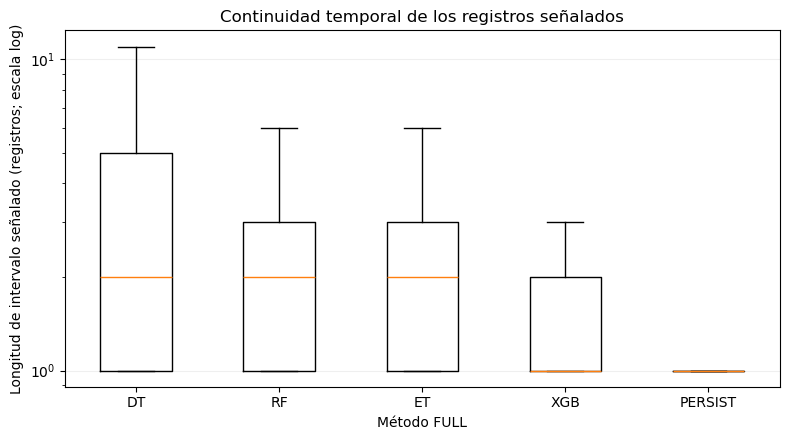

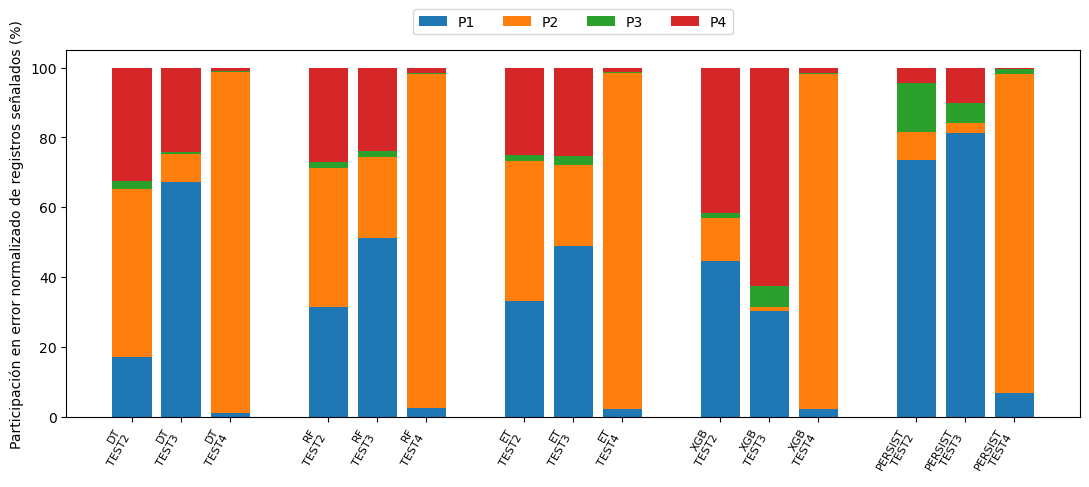

In [6]:
order=['DT','RF','ET','XGB','PERSIST']
plotdata=[intervals.loc[intervals.modelo==m,'registros'].to_numpy() for m in order]
fig,ax=plt.subplots(figsize=(8,4.5))
ax.boxplot(plotdata,labels=order,showfliers=False)
ax.set_yscale('log')
ax.set_ylabel('Longitud de intervalo señalado (registros; escala log)')
ax.set_xlabel('Método FULL')
ax.set_title('Continuidad temporal de los registros señalados')
ax.grid(axis='y',alpha=.2)
fig.tight_layout()
fig.savefig(OUT/'fig_etapa3_duracion_intervalos.png',dpi=220)
fig.savefig(OUT/'fig_etapa3_duracion_intervalos.pdf')
plt.show()

# Cada barra corresponde al porcentaje relativo del error cuadrático normalizado,
# SUMADO sobre todos los registros señalados del TEST; suman 100 % dentro de cada barra.
fig,ax=plt.subplots(figsize=(11,5))
positions=[];labels=[]
for mi,m in enumerate(order):
    for ti,t in enumerate(TESTS):
        positions.append(mi*4+ti)
        labels.append(f'{m}\n{t.upper()}')
current=np.zeros(len(positions))
for comp in COMPONENTS:
    values=[]
    for m in order:
        for t in TESTS:
            rr=components[(components.modelo==m)&(components.test==t)&(components.componente==comp)]
            values.append(float(rr.fraccion_error_cuadratico_pct.iloc[0]))
    ax.bar(positions,values,bottom=current,label=comp)
    current+=np.asarray(values)
ax.set_xticks(positions,labels,rotation=60,ha='right',fontsize=8)
ax.set_ylabel('Participación en error normalizado de registros señalados (%)')
ax.set_ylim(0,105)
ax.legend(ncol=4,loc='upper center',bbox_to_anchor=(.5,1.13))
fig.tight_layout()
fig.savefig(OUT/'fig_etapa3_componentes_error.png',dpi=220)
fig.savefig(OUT/'fig_etapa3_componentes_error.pdf')
plt.show()


## 6. Cierre de cobertura y archivos para la discusión

Se escriben resultados exclusivamente descriptivos. Los episodios etiquetados permiten un contraste temporal limitado, no una verdad de terreno de todas las anomalías. El notebook no decide automáticamente qué modelo es mejor ni si una desviación implica cambio de régimen.

In [7]:
expected_files=['00_cobertura.csv','01_continuidad_temporal.csv','02_intervalos_senalados.csv',
  '03_bloques_temporales.csv','04_episodios_contraste.csv',
  '05_contribucion_componentes.csv','06_contribucion_senales.csv','07_verificacion_score.csv',
  'fig_etapa3_duracion_intervalos.png','fig_etapa3_componentes_error.png']
assert set(map(tuple,coverage[['modelo','test']].to_numpy()))==EXPECTED
assert episodes.groupby('modelo').size().eq(51).all(), 'Revisar el número de episodios visible por modelo'
assert summary.registros.sum()==5*274710, 'Revisar número de registros esperados'
assert all((OUT/name).is_file() for name in expected_files)
final=pd.DataFrame([{'archivo':name,'existe':(OUT/name).is_file(),
     'tamano_bytes':(OUT/name).stat().st_size if (OUT/name).is_file() else None} for name in expected_files])
final.to_csv(OUT/'08_inventario_etapa3.csv',index=False)
print(final.to_string(index=False))
print('\nEtapa 3 calculada. Compartir los CSV 01, 04, 05 y 07 y las dos figuras.')


                           archivo  existe  tamano_bytes
                  00_cobertura.csv    True           545
       01_continuidad_temporal.csv    True          1253
       02_intervalos_senalados.csv    True       2089292
         03_bloques_temporales.csv    True        130744
        04_episodios_contraste.csv    True         22913
   05_contribucion_componentes.csv    True          4737
       06_contribucion_senales.csv    True         15233
         07_verificacion_score.csv    True           539
fig_etapa3_duracion_intervalos.png    True         63407
  fig_etapa3_componentes_error.png    True         70459

Etapa 3 calculada. Compartir los CSV 01, 04, 05 y 07 y las dos figuras.
